# Decision Tree Classifier

Problem -  Design and develop a Machine learning model that can help in Loan repayment Prediction using Decision Tree algorithm


Dataset  - 
The Loan Repayment dataset is made up of 1000 rows and six columns. Each row represents information about a particular person that relates to loan repayment. This dataset is perfect for classification algorithms such as the decision tree. The six columns are the following.

Initial payment.<br/>
Last payment.<br/>
Credit score.<br/>
House number.<br/>
Sum.<br/>
Result.<br/>




## Step 1 — Import Required Libraries
**Task:** Complete the imports.

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)




## Step 2 — Load the Loan Repayment dataset
**Task:** Read the CSV file from the codebase and display top rows.

In [34]:
df = pd.read_csv('Loans_Dataset.csv')
df.head()


,initial_payment,last_payment,credit_score,house_number,sum,result
0,201,10018,250,3046,13515,yes
1,205,10016,395,3044,13660,yes
2,257,10129,109,3251,13746,yes
3,246,10064,324,3137,13771,yes
4,117,10115,496,3094,13822,yes


## Step 3 — Explore & Analyze the Dataset (EDA)
**Task:** Data analysis and preprocessing

Shape: (1004, 6)

Columns: ['initial_payment', 'last_payment', 'credit_score', 'house_number', 'sum', 'result']

Missing values:
 initial_payment    0
last_payment       0
credit_score       0
house_number       0
sum                0
result             0
dtype: int64


,initial_payment,last_payment,credit_score,house_number,sum
count,1004.000000,1004.000000,1004.000000,1004.000000,1004.000000
mean,294.662351,12473.009960,528.902390,4041.282869,17744.012948
std,115.844218,1442.134231,259.681745,618.431417,9594.659715
min,100.000000,10005.000000,100.000000,3003.000000,13515.000000
25%,195.750000,11213.500000,302.750000,3546.500000,16081.250000
50%,290.000000,12467.000000,518.000000,4046.000000,17383.000000
75%,398.000000,13690.000000,755.000000,4508.750000,18608.250000
max,500.000000,14999.000000,997.000000,9876.000000,246789.000000


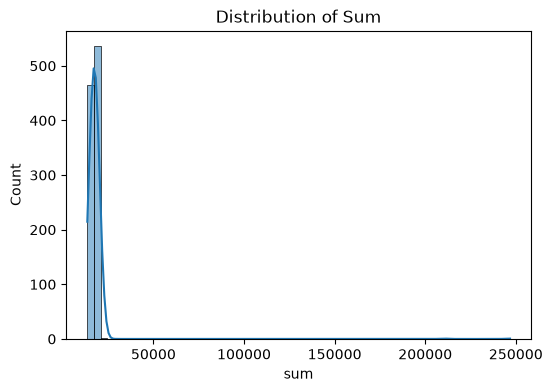


Correlation Matrix:
                  initial_payment  last_payment  credit_score  house_number  \
initial_payment         1.000000     -0.013536     -0.009421      0.071100   
last_payment           -0.013536      1.000000     -0.000805      0.057410   
credit_score           -0.009421     -0.000805      1.000000      0.034885   
house_number            0.071100      0.057410      0.034885      1.000000   
sum                     0.050698      0.213237      0.068387      0.412303   
result                 -0.048464     -0.805640     -0.076326     -0.202827   

                      sum    result  
initial_payment  0.050698 -0.048464  
last_payment     0.213237 -0.805640  
credit_score     0.068387 -0.076326  
house_number     0.412303 -0.202827  
sum              1.000000 -0.092830  
result          -0.092830  1.000000  


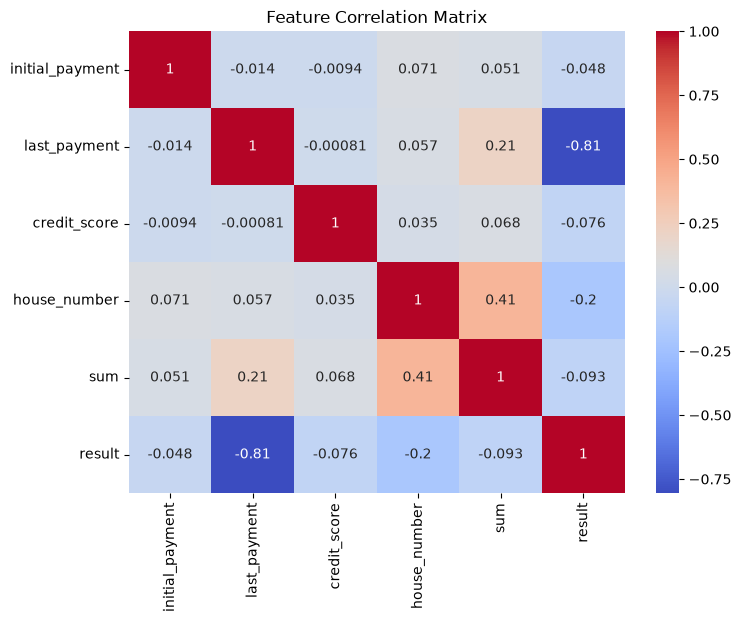

In [35]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum())
display(df.describe())

le = LabelEncoder()
df['result'] = le.fit_transform(df['result'])

plt.figure(figsize=(6, 4))
sns.histplot(df['sum'], kde=True)
plt.title("Distribution of Sum")
plt.show()

print("\nCorrelation Matrix:\n", df.corr())
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation Matrix")
plt.show()


## Step 4 - Write code to clean data and drop insignificant column(s)

In [36]:
df = df.drop_duplicates()
df = df.dropna()

df = df.drop(columns=['house_number'])
df.head()


,initial_payment,last_payment,credit_score,sum,result
0,201,10018,250,13515,1
1,205,10016,395,13660,1
2,257,10129,109,13746,1
3,246,10064,324,13771,1
4,117,10115,496,13822,1


## Step 5 — Split Dataset into Training and Test Sets
**Task:** Use `train_test_split` with a test size and random state.

In [37]:
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0
)





## Step 5.5 — Scaling


In [38]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

## Step 6 — Train the Decision Tree Classifier Model
**Task:** Create and fit the model.

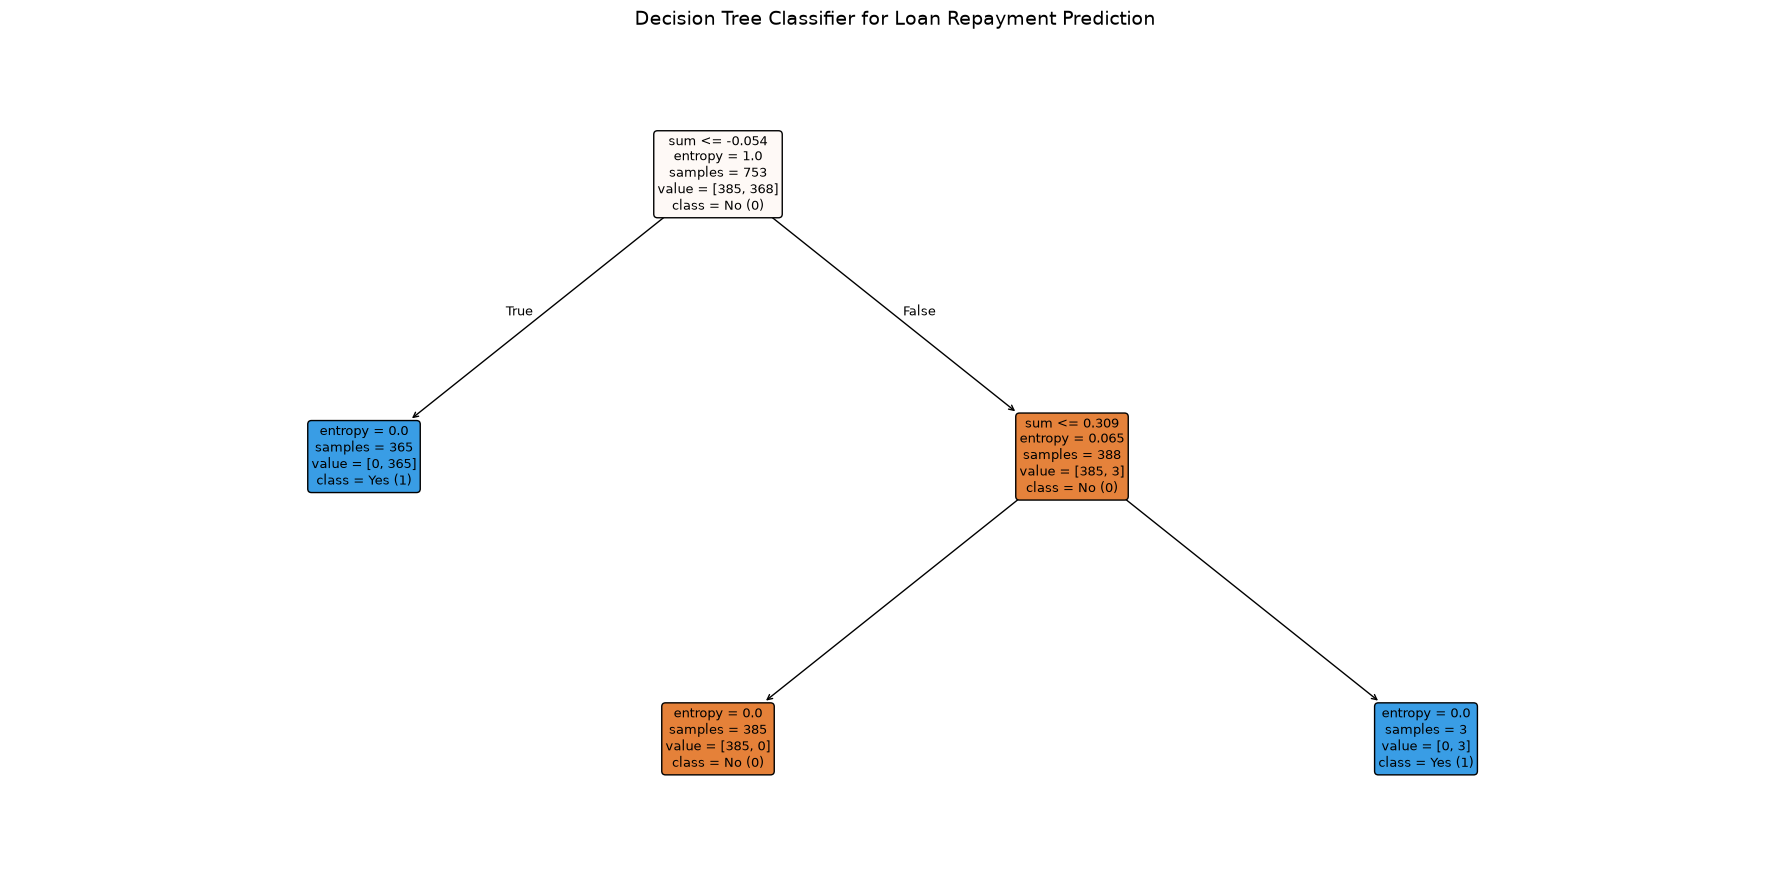

In [39]:
classifier = DecisionTreeClassifier(criterion='entropy', random_state=0)
classifier.fit(X_train, y_train)

plt.figure(figsize=(18, 9))
plot_tree(
    classifier,
    feature_names=df.columns[:-1],
    class_names=['No (0)', 'Yes (1)'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree Classifier for Loan Repayment Prediction", fontsize=14)
plt.tight_layout()
plt.show()




## Step 7 — Make Predictions
**Task:** Predict class outcomes and statistics.

[[0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]

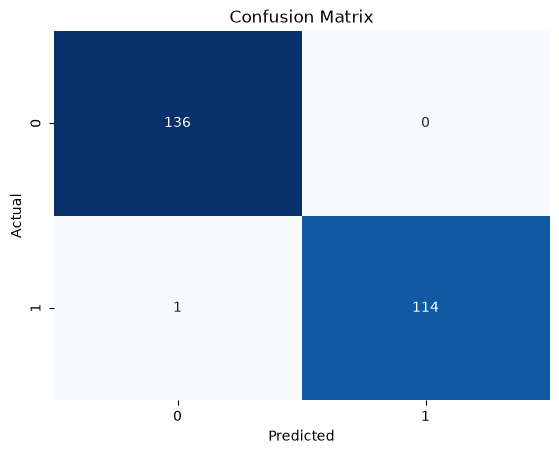

In [43]:
y_pred = classifier.predict(X_test)
print(np.concatenate((y_pred.reshape(len(y_pred), 1), y_test.reshape(len(y_test), 1)), 1))

print(f"Classification Report:\n{classification_report(y_test, y_pred)}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")

cf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(cf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()



## Step 8 — Single Sample Prediction Example 

In [44]:
sample_prediction = classifier.predict(sc.transform([[250, 10500, 450, 14200]]))
print("Predicted class:", sample_prediction)


Predicted class: [1]
